# Feature Correlation and Regularization in Rice Classification

## Baseline and Regularized Logistic Regression

**Course:** CP322 - Machine Learning

**By:** Zohra Haidary

### Research Question

How does multicollinearity affect logistic regression
coefficients in rice variety classification, and how
do L1 and L2 regularization influence coefficient
stability and predictive performance compared to
unregularized logistic regression and non-linear models?

In [1]:
import sys
import numpy as np
import pandas as pd
import sklearn

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Scikit-learn version:", sklearn.__version__)

print("Environment ready!")

Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Python executable: c:\Users\hp\Desktop\University\year4\fall\CP322 - Machine\CP322-Rice-Classification\.venv\Scripts\python.exe
Scikit-learn version: 1.9.1
Environment ready!


In [2]:
from pathlib import Path
from scipy.io import arff

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

RANDOM_STATE = 42

print("All libraries imported successfully.")

All libraries imported successfully.


## 1. Dataset Loading

The UCI Rice (Cammeo and Osmancik) dataset contains
3,810 observations and seven morphological features.

The objective is to classify rice grains into one
of two varieties: Cammeo or Osmancik.

In [3]:
# Locate the dataset
data_path = Path("../data/Rice_Cammeo_Osmancik.arff")

if not data_path.exists():
    data_path = Path("data/Rice_Cammeo_Osmancik.arff")

# Load the ARFF dataset
data, metadata = arff.loadarff(data_path)

# Convert the dataset into a pandas DataFrame
df = pd.DataFrame(data)

# Decode class labels
df["Class"] = df["Class"].str.decode("utf-8")

# Display dataset information
print("Dataset shape:", df.shape)
print("Number of observations:", df.shape[0])
print("Number of features:", df.shape[1] - 1)

df.head()

Dataset shape: (3810, 8)
Number of observations: 3810
Number of features: 7


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231.0,525.578979,229.749878,85.093788,0.928882,15617.0,0.572896,Cammeo
1,14656.0,494.311005,206.020065,91.730972,0.895405,15072.0,0.615436,Cammeo
2,14634.0,501.122009,214.106781,87.768288,0.912118,14954.0,0.693259,Cammeo
3,13176.0,458.342987,193.337387,87.448395,0.891861,13368.0,0.640669,Cammeo
4,14688.0,507.166992,211.743378,89.312454,0.906691,15262.0,0.646024,Cammeo


## 2. Temporary Data Preprocessing

A temporary preprocessing pipeline is used to develop
and test the logistic regression models independently.
The final experiments will use the shared preprocessing
pipeline provided by the team.

In [4]:
# Inspect the dataset
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
print(df["Class"].value_counts())

print("\nData types:")
print(df.dtypes)

Missing values:
Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
Class                0
dtype: int64

Duplicate rows: 0

Class distribution:
Class
Osmancik    2180
Cammeo      1630
Name: count, dtype: int64

Data types:
Area                 float64
Perimeter            float64
Major_Axis_Length    float64
Minor_Axis_Length    float64
Eccentricity         float64
Convex_Area          float64
Extent               float64
Class                    str
dtype: object


In [5]:
# Input features
X = df.drop(columns=["Class"])

# Encode the target variable
y = df["Class"].map({
    "Cammeo": 0,
    "Osmancik": 1
})

feature_names = X.columns.tolist()

assert y.notna().all(), "Unexpected class labels found."

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature names:")
print(feature_names)

print("\nEncoded class distribution:")
print(y.value_counts())

X shape: (3810, 7)
y shape: (3810,)

Feature names:
['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']

Encoded class distribution:
Class
1    2180
0    1630
Name: count, dtype: int64


In [6]:
# Create a temporary stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True))

Training features: (3048, 7)
Testing features: (762, 7)
Training labels: (3048,)
Testing labels: (762,)

Training class proportions:
Class
1    0.572178
0    0.427822
Name: proportion, dtype: float64

Testing class proportions:
Class
1    0.572178
0    0.427822
Name: proportion, dtype: float64


In [7]:
# Configure stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Stratified 5-fold cross-validation configured.")

Stratified 5-fold cross-validation configured.


## 3. Unregularized Logistic Regression

The baseline logistic regression model is trained without
regularization to investigate the effects of multicollinearity
on learned coefficients and predictive performance.

Feature standardization is performed within a pipeline
to prevent data leakage.

In [8]:
# Create an unregularized logistic regression pipeline
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=np.inf,
        solver="lbfgs",
        max_iter=10000,
        tol=1e-8,
        random_state=RANDOM_STATE
    ))
])

# Train the model
baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression trained successfully.")

Baseline Logistic Regression trained successfully.


In [9]:
# Extract the fitted logistic regression model
baseline_lr = baseline_model.named_steps["model"]

# Extract coefficients
baseline_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": baseline_lr.coef_[0]
})

print("Baseline intercept:", baseline_lr.intercept_[0])
print("Number of iterations:", baseline_lr.n_iter_[0])

baseline_coefficients

Baseline intercept: 0.6739342781312252
Number of iterations: 70


,Feature,Coefficient
0,Area,11.260016
1,Perimeter,3.607005
2,Major_Axis_Length,-3.220732
3,Minor_Axis_Length,1.580678
4,Eccentricity,-0.455387
5,Convex_Area,-17.289126
6,Extent,0.084013


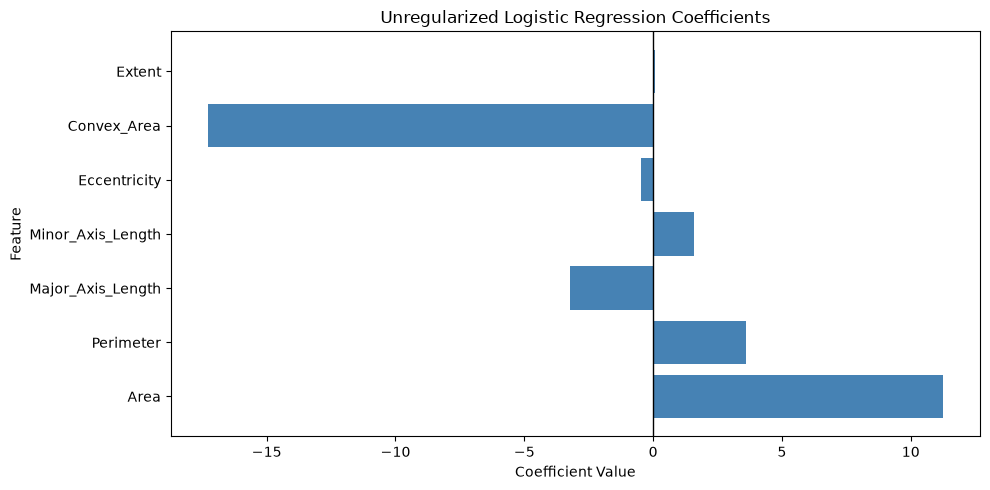

In [10]:
plt.figure(figsize=(10, 5))

plt.barh(
    baseline_coefficients["Feature"],
    baseline_coefficients["Coefficient"],
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Unregularized Logistic Regression Coefficients")

plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import cross_val_score

baseline_cv_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Cross-validation scores:", baseline_cv_scores)

print(
    "Mean CV accuracy:",
    baseline_cv_scores.mean()
)

print(
    "CV standard deviation:",
    baseline_cv_scores.std()
)

Cross-validation scores: [0.93770492 0.93606557 0.93278689 0.92118227 0.93431856]
Mean CV accuracy: 0.9324116396134485
CV standard deviation: 0.005852281578756113


## 4. Ridge Logistic Regression (L2)

L2 regularization introduces a squared coefficient penalty
to reduce large model weights and address potential
multicollinearity among correlated morphological features.

The regularization strength is selected using stratified
five-fold cross-validation.

In [12]:
# Create Ridge Logistic Regression pipeline
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        l1_ratio=0.0,
        C=1.0,
        solver="lbfgs",
        max_iter=10000,
        tol=1e-8,
        random_state=RANDOM_STATE
    ))
])

print("Ridge Logistic Regression configured.")

Ridge Logistic Regression configured.


In [13]:
# Candidate regularization strengths
C_values = [
    0.001,
    0.01,
    0.1,
    1,
    10,
    100,
    1000
]

ridge_param_grid = {
    "model__C": C_values
}

print("Candidate C values:", C_values)

Candidate C values: [0.001, 0.01, 0.1, 1, 10, 100, 1000]


In [14]:
# Tune Ridge regularization strength
ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

# Train and tune using training data only
ridge_grid.fit(X_train, y_train)

# Retrieve the best model
ridge_model = ridge_grid.best_estimator_

print("Best Ridge C:", ridge_grid.best_params_)
print("Best Ridge CV accuracy:", ridge_grid.best_score_)

Best Ridge C: {'model__C': 100}
Best Ridge CV accuracy: 0.9337247301407844


In [15]:
ridge_cv_results = pd.DataFrame(
    ridge_grid.cv_results_
)

ridge_cv_summary = ridge_cv_results[
    [
        "param_model__C",
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].copy()

ridge_cv_summary.columns = [
    "C",
    "Mean Training Accuracy",
    "Mean Validation Accuracy",
    "Validation Std",
    "Rank"
]

ridge_cv_summary

,C,Mean Training Accuracy,Mean Validation Accuracy,Validation Std,Rank
0,0.001,0.922572,0.922898,0.007063,7
1,0.010,0.931266,0.930442,0.011614,6
2,0.100,0.932989,0.932740,0.008646,4
3,1.000,0.933153,0.933068,0.009728,3
4,10.000,0.935941,0.933395,0.009801,2
5,100.000,0.934711,0.933725,0.006131,1
6,1000.000,0.934957,0.932412,0.005852,5


In [16]:
# Extract trained Ridge model
ridge_lr = ridge_model.named_steps["model"]

# Store learned coefficients
ridge_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": ridge_lr.coef_[0]
})

print("Ridge intercept:", ridge_lr.intercept_[0])
print("Number of iterations:", ridge_lr.n_iter_[0])

ridge_coefficients

Ridge intercept: 0.6803455645455786
Number of iterations: 68


,Feature,Coefficient
0,Area,9.400866
1,Perimeter,2.909608
2,Major_Axis_Length,-2.610567
3,Minor_Axis_Length,1.701221
4,Eccentricity,-0.484847
5,Convex_Area,-15.374580
6,Extent,0.074192


In [17]:
coefficient_comparison = pd.DataFrame({
    "Feature": feature_names,
    "Baseline": baseline_lr.coef_[0],
    "Ridge": ridge_lr.coef_[0]
})

coefficient_comparison

,Feature,Baseline,Ridge
0,Area,11.260016,9.400866
1,Perimeter,3.607005,2.909608
2,Major_Axis_Length,-3.220732,-2.610567
3,Minor_Axis_Length,1.580678,1.701221
4,Eccentricity,-0.455387,-0.484847
5,Convex_Area,-17.289126,-15.374580
6,Extent,0.084013,0.074192


In [18]:
print(
    "Baseline L2 norm:",
    np.linalg.norm(baseline_lr.coef_[0])
)

print(
    "Ridge L2 norm:",
    np.linalg.norm(ridge_lr.coef_[0])
)

Baseline L2 norm: 21.25555006238924
Ridge L2 norm: 18.52483727142263


## 5. Lasso Logistic Regression (L1)

L1 regularization introduces an absolute coefficient
penalty that encourages coefficient shrinkage and
sparsity.

This experiment investigates whether redundant
morphological features can be eliminated while
maintaining predictive performance.

The regularization strength is selected using
stratified five-fold cross-validation.